# Item Cold Start - Content-Based Recommendation of New Movies
**Project:** Hybrid Movie Recommendation System (HetRec 2011 - MovieLens 2K) &nbsp;|&nbsp; **Component:** Item Cold Start (Member 3)

## 1. Objective
A *new* movie has no (or very few) ratings, so collaborative filtering cannot recommend it.
This notebook implements the **Item Cold Start** component, which recommends such movies from their **metadata** instead:

1. **TF-IDF** turns the text metadata (genres, tags, actors, directors, countries) of every movie into a sparse vector.
2. **Cosine similarity** measures how alike two vectors are (movie-to-movie) or how well a movie fits a **user preference profile**.
3. **Ranking metrics** (Precision@K, Recall@K, NDCG@K, Catalog Coverage) measure how well the ranked list matches ratings that were *hidden* from the model.

**Workflow**

| Step | What happens |
|---|---|
| Load | Read the four shared CSV files from `dataset/processed/` (read-only). |
| Simulate | Create cold-start (0 ratings), limited-rating (1-5) and warm (>5) movie groups; hide their interactions from training. |
| Analyse | Measure metadata availability. |
| Model | Fit three TF-IDF models: **A** genres, **B** tags, **C** combined `content`. |
| Recommend | `recommend_similar_movies` (item-to-item) and `recommend_cold_start_movies` (user profile -> cold-start movies). |
| Evaluate | Compare A/B/C per group on held-out ratings, with no test leakage. |

All reusable code lives in `src/item_cold_start.py`; this notebook calls it step by step.

## 2. Importing Libraries
The notebook finds the project root automatically (it works from the project root *or* from `notebooks/`), so no paths have to be edited.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the project root (the folder that contains src/item_cold_start.py)
here = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [here, *here.parents] if (p / "src" / "item_cold_start.py").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook inside the project repository (src/item_cold_start.py not found).")
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import item_cold_start as ics          # our reusable module

RANDOM_STATE = 42                      # one fixed seed for the whole experiment
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)

print("Project root:", PROJECT_ROOT)

Project root: <your-project-folder>


## 3. Loading Common Processed Data
`load_processed_data` reads the four shared files, **checks that the required columns exist** and that `movieID` has the same data type in every file.
The files are only read - never written. `userID` and `movieID` values are kept exactly as they are.

In [2]:
paths = ics.get_project_paths(PROJECT_ROOT)       # also creates outputs/results and outputs/figures if missing
data = ics.load_processed_data(paths["data_dir"])

ratings, movies, train, test = data["ratings"], data["movies"], data["train"], data["test"]
print("Data folder   :", paths["data_dir"])
print("Results folder:", paths["results_dir"])
print("Figures folder:", paths["figures_dir"])
print("All required columns found and movieID dtypes are consistent.")

Data folder   : <your-project-folder>/dataset/processed
Results folder: <your-project-folder>/outputs/results
Figures folder: <your-project-folder>/outputs/figures
All required columns found and movieID dtypes are consistent.


## 4. Dataset Exploration
Shapes, columns, missing values, users, movies, interactions, rating distribution, metadata availability and `movieID` consistency.

In [3]:
datasets = {"ratings_clean": ratings, "movie_features": movies, "train_ratings": train, "test_ratings": test}

print("DATASET SHAPES")
for name, df in datasets.items():
    print(f"  {name:15s} rows = {df.shape[0]:>8,}   columns = {df.shape[1]}")

print("\nCOLUMN NAMES")
for name, df in datasets.items():
    print(f"  {name}: {list(df.columns)}")

DATASET SHAPES
  ratings_clean   rows =  855,598   columns = 9
  movie_features  rows =   10,197   columns = 27
  train_ratings   rows =  683,631   columns = 9
  test_ratings    rows =  171,808   columns = 9

COLUMN NAMES
  ratings_clean: ['userID', 'movieID', 'rating', 'date_day', 'date_month', 'date_year', 'date_hour', 'date_minute', 'date_second']
  movie_features: ['movieID', 'title', 'imdbID', 'spanishTitle', 'imdbPictureURL', 'year', 'rtID', 'rtAllCriticsRating', 'rtAllCriticsNumReviews', 'rtAllCriticsNumFresh', 'rtAllCriticsNumRotten', 'rtAllCriticsScore', 'rtTopCriticsRating', 'rtTopCriticsNumReviews', 'rtTopCriticsNumFresh', 'rtTopCriticsNumRotten', 'rtTopCriticsScore', 'rtAudienceRating', 'rtAudienceNumRatings', 'rtAudienceScore', 'rtPictureURL', 'genres', 'tags', 'actors', 'directors', 'countries', 'content']
  train_ratings: ['userID', 'movieID', 'rating', 'date_day', 'date_month', 'date_year', 'date_hour', 'date_minute', 'date_second']
  test_ratings: ['userID', 'movieID',

In [4]:
print("MISSING VALUES (only columns that have any)")
for name, df in datasets.items():
    missing = df.isna().sum()
    missing = missing[missing > 0]
    print(f"  {name}: " + ("none" if missing.empty else ""))
    if not missing.empty:
        print(missing.to_string().replace("\n", "\n      "))

MISSING VALUES (only columns that have any)
  ratings_clean: none
  movie_features: 
imdbPictureURL     181
      rtID               311
      tags              3042
      actors              23
      directors           42
      countries            8
  train_ratings: none
  test_ratings: none


In [5]:
summary = pd.DataFrame({
    "unique_users":  [ratings.userID.nunique(), train.userID.nunique(), test.userID.nunique(), np.nan],
    "unique_movies": [ratings.movieID.nunique(), train.movieID.nunique(), test.movieID.nunique(), movies.movieID.nunique()],
    "interactions":  [len(ratings), len(train), len(test), np.nan],
}, index=["ratings_clean", "train_ratings", "test_ratings", "movie_features (catalogue)"])
print(summary.to_string())

dist = ratings["rating"].value_counts().sort_index().rename("count").to_frame()
dist["percent"] = (100 * dist["count"] / dist["count"].sum()).round(2)
print("\nRATING DISTRIBUTION (ratings_clean)")
print(dist.to_string())
print("\nMissing ratings in ratings_clean:", int(ratings["rating"].isna().sum()), "(none are ever replaced by zero)")

                            unique_users  unique_movies  interactions
ratings_clean                     2113.0          10109      855598.0
train_ratings                     2113.0           9972      683631.0
test_ratings                      2113.0           8346      171808.0
movie_features (catalogue)           NaN          10197           NaN

RATING DISTRIBUTION (ratings_clean)
         count  percent
rating                 
0.5      13488     1.58
1.0      21535     2.52
1.5      18328     2.14
2.0      57188     6.68
2.5      62454     7.30
3.0     155918    18.22
3.5     150582    17.60
4.0     215773    25.22
4.5      88652    10.36
5.0      71680     8.38

Missing ratings in ratings_clean: 0 (none are ever replaced by zero)


In [6]:
print("MOVIE METADATA AVAILABILITY (non-empty values)")
for field in ics.METADATA_FIELDS + ["content"]:
    available = (movies[field].fillna("").astype(str).str.strip() != "")
    print(f"  {field:10s} {available.sum():>6,} / {len(movies):,}  ({100 * available.mean():5.1f}%)")

print("\nmovieID DATA TYPES")
print(ics.check_movieid_dtypes(datasets).to_string(index=False))

print("\nCONSISTENCY CHECKS")
print("  movies rated but missing from movie_features :", len(set(ratings.movieID) - set(movies.movieID)))
print("  catalogue movies with no rating at all       :", len(set(movies.movieID) - set(ratings.movieID)))
print("  catalogue movies with no TRAIN rating        :", len(set(movies.movieID) - set(train.movieID)))
print("  test movies that never appear in train       :", len(set(test.movieID) - set(train.movieID)))
print("  (user, movie) pairs present in both train and test:",
      len(set(zip(train.userID, train.movieID)) & set(zip(test.userID, test.movieID))))
print("  rows in ratings_clean not in train or test   :", len(ratings) - len(train) - len(test))

MOVIE METADATA AVAILABILITY (non-empty values)
  genres     10,197 / 10,197  (100.0%)
  tags        7,155 / 10,197  ( 70.2%)
  actors     10,174 / 10,197  ( 99.8%)
  directors  10,155 / 10,197  ( 99.6%)
  countries  10,189 / 10,197  ( 99.9%)
  content    10,197 / 10,197  (100.0%)

movieID DATA TYPES
       dataset movieID_dtype
 ratings_clean         int64
movie_features         int64
 train_ratings         int64
  test_ratings         int64

CONSISTENCY CHECKS
  movies rated but missing from movie_features : 0
  catalogue movies with no rating at all       : 88
  catalogue movies with no TRAIN rating        : 225
  test movies that never appear in train       : 0
  (user, movie) pairs present in both train and test: 0
  rows in ratings_clean not in train or test   : 159


## 5. Experimental Setup
**How the cold-start simulation works** (implemented in `simulate_item_cold_start`):

| Group | Selection (seed 42) | Training data kept | Held-out (hidden) data |
|---|---|---|---|
| **Cold-start** (0 ratings) | random movies with >= 20 interactions in train+test | **none** - all training ratings removed | removed training ratings + the movie's original test ratings |
| **Limited-rating** (1-5) | different random movies, same rule | **at most 5** randomly chosen training ratings per movie | the other training ratings + original test ratings |
| **Warm** (> 5) | different random movies with >= 20 training and >= 5 test ratings | **all** training ratings | original test ratings |

* Groups are **disjoint**; each has the same number of movies so that results are comparable.
* Eligibility is decided from interaction **counts** only (so every group has enough held-out ratings to evaluate) - never from rating values.
* The held-out interactions are stored in a **separate table** and are never used to build profiles or recommendations.
* The shared CSV files are not touched; the simulation works on copies and returns a new training set.
* All movie metadata is kept, including that of cold-start movies (a new movie is known by its metadata even though nobody has rated it).

**Evaluation protocol**
* A user is evaluated on a group only if they have >= 10 training ratings, >= 5 *positive* (>= 4.0) training ratings (enough to build a profile) and >= 1 relevant held-out movie in that group.
* The recommender ranks the group's movies (excluding movies the user already rated in training); a held-out movie is **relevant if its rating >= 4.0**. Movies that are low-rated or unrated count as not relevant.

In [7]:
CONFIG = dict(
    n_cold=300, n_limited=300, n_warm=300,       # movies per group
    limited_max_train=5,                         # limited group keeps <= 5 training ratings
    warm_min_train=20,                           # warm movies keep all of >= 20 training ratings
    min_total_interactions=20,                   # eligibility for cold / limited selection
    min_heldout_interactions=5,                  # eligibility for warm selection
    random_state=RANDOM_STATE,
)
EVAL = dict(
    k_values=(5, 10),
    relevance_threshold=4.0,                     # held-out rating >= 4.0 is relevant
    min_train_ratings=10,
    min_positive_train=5,
)
print("Simulation config:", CONFIG)
print("Evaluation config:", EVAL)

Simulation config: {'n_cold': 300, 'n_limited': 300, 'n_warm': 300, 'limited_max_train': 5, 'warm_min_train': 20, 'min_total_interactions': 20, 'min_heldout_interactions': 5, 'random_state': 42}
Evaluation config: {'k_values': (5, 10), 'relevance_threshold': 4.0, 'min_train_ratings': 10, 'min_positive_train': 5}


## 6. Cold-Start Simulation
`simulate_item_cold_start` returns the new training set (`train`), the separate held-out set (`heldout`), the movie IDs of each group and a movie-level summary.
It also verifies its own integrity (cold movies really have zero training ratings, no user-movie pair is in both train and held-out, ...).

In [8]:
sim = ics.simulate_item_cold_start(train, test, movies, **CONFIG)

sim_train = sim["train"]          # training ratings used for ALL profiles / recommendations
heldout   = sim["heldout"]        # hidden ground truth, used only for evaluation
groups    = sim["groups"]         # dict: category -> array of movieIDs
cold_ids  = groups[ics.CATEGORY_COLD]

print("INTEGRITY CHECKS")
for check, ok in ics.validate_simulation(sim).items():
    print(f"  [{'OK' if ok else 'FAIL'}] {check}")

print(f"\nOriginal train rows : {len(train):,}  (unchanged)")
print(f"Simulated train rows: {len(sim_train):,}  ({len(train) - len(sim_train):,} moved to held-out)")
print(f"Held-out rows       : {len(heldout):,}")

INTEGRITY CHECKS
  [OK] cold movies have 0 training ratings
  [OK] limited movies have 1..limited_max_train ratings
  [OK] warm movies have > 5 training ratings
  [OK] no user-movie pair is in both train and held-out
  [OK] groups are disjoint
  [OK] every selected movie has held-out interactions

Original train rows : 683,631  (unchanged)
Simulated train rows: 613,106  (70,525 moved to held-out)
Held-out rows       : 98,841


In [9]:
overview = sim["summary"].groupby("category").agg(
    movies=("movieID", "size"),
    train_ratings_before=("n_train_original", "sum"),
    train_ratings_after=("n_train_simulated", "sum"),
    min_train_after=("n_train_simulated", "min"),
    max_train_after=("n_train_simulated", "max"),
    heldout_interactions=("n_heldout", "sum"),
).loc[ics.CATEGORIES]
print(overview.to_string())

print("\nHeld-out interactions by origin")
print(heldout.groupby(["category", "source"]).size().unstack().loc[ics.CATEGORIES].to_string())

relevant = heldout[heldout.rating >= EVAL["relevance_threshold"]].groupby("category").size().loc[ics.CATEGORIES]
print("\nRelevant held-out interactions (rating >= 4.0):")
print(relevant.to_string())

# Save the (small) group definition so teammates can reproduce / inspect the experiment
group_file = paths["results_dir"] / "cold_start_simulation_groups.csv"
sim["summary"].to_csv(group_file, index=False)
print("\nSaved:", group_file.relative_to(PROJECT_ROOT))

                movies  train_ratings_before  train_ratings_after  min_train_after  max_train_after  heldout_interactions
category                                                                                                                 
cold_start         300                 37058                    0                0                0                 46307
limited_rating     300                 34967                 1500                5                5                 42016
warm               300                 41915                41915               20              884                 10518

Held-out interactions by origin
source          original_test  removed_from_train
category                                         
cold_start             9249.0             37058.0
limited_rating         8549.0             33467.0
warm                  10518.0                 NaN

Relevant held-out interactions (rating >= 4.0):
category
cold_start        21372
limited_rating    18393
w

## 7. Metadata Analysis
Content-based filtering is only as good as the metadata. A value counts as *available* if it is neither missing nor blank.
`overall_coverage` is the mean availability of the five fields; `all_five_fields` is the share of movies that have every field.

In [10]:
coverage = ics.analyze_metadata_coverage(movies, scopes={
    "Cold-start movies": cold_ids,
    "Limited-rating movies": groups[ics.CATEGORY_LIMITED],
    "Warm movies": groups[ics.CATEGORY_WARM],
})
coverage_file = paths["results_dir"] / "metadata_coverage.csv"
coverage.to_csv(coverage_file, index=False)
print("Saved:", coverage_file.relative_to(PROJECT_ROOT), "\n")

print("Total movies per scope:")
print(coverage.drop_duplicates("scope")[["scope", "total_movies"]].to_string(index=False))

print("\nAvailability counts")
print(coverage.pivot(index="metadata_field", columns="scope", values="available_count")
      .loc[ics.METADATA_FIELDS + ["all_five_fields"]].to_string())
print("\nAvailability percentages (%)")
print(coverage.pivot(index="metadata_field", columns="scope", values="availability_pct")
      .loc[ics.METADATA_FIELDS + ["overall_coverage", "all_five_fields"]].round(2).to_string())

Saved: outputs/results/metadata_coverage.csv 

Total movies per scope:
                scope  total_movies
           All movies         10197
    Cold-start movies           300
Limited-rating movies           300
          Warm movies           300

Availability counts
scope            All movies  Cold-start movies  Limited-rating movies  Warm movies
metadata_field                                                                    
genres              10197.0              300.0                  300.0        300.0
tags                 7155.0              274.0                  273.0        282.0
actors              10174.0              299.0                  300.0        300.0
directors           10155.0              298.0                  299.0        300.0
countries           10189.0              300.0                  300.0        300.0
all_five_fields      7115.0              273.0                  273.0        282.0

Availability percentages (%)
scope             All movies  Cold

## 8. Genre-based TF-IDF (Model A)
**How TF-IDF works here.** Every movie is a short "document" made of words (e.g. the genres *Adventure Animation Children*).
*Term frequency* counts how often a word occurs in the movie; *inverse document frequency* down-weights words that occur in many movies
(*Drama* says little, *Film-Noir* says a lot). Each movie becomes a sparse, L2-normalised vector, stored as a `scipy` sparse matrix
(never converted to a dense array). Row *i* of the matrix is row *i* of the prepared movie table; `movie_id_to_index` stores that mapping.

`prepare_movie_features` first makes a safe copy: missing text -> empty string, whitespace cleaned, and an empty `content` is rebuilt from the other fields.

In [11]:
movies_prep = ics.prepare_movie_features(movies)           # safe copy; the original table stays untouched
movie_id_to_index = ics.build_movie_index(movies_prep)     # movieID -> TF-IDF matrix row
assert (movies_prep["movieID"].to_numpy() == movies["movieID"].to_numpy()).all()   # same IDs, same order

tfidf_models = {}          # name -> {"column", "vectorizer", "matrix"}

def register_model(name, column):
    vectorizer, matrix = ics.build_tfidf_model(movies_prep, column)
    tfidf_models[name] = {"column": column, "vectorizer": vectorizer, "matrix": matrix}
    zero_rows = np.asarray(matrix.getnnz(axis=1) == 0)
    cold_rows = [movie_id_to_index[m] for m in cold_ids]
    print(f"{name}: matrix shape {matrix.shape}, vocabulary {len(vectorizer.vocabulary_):,} terms, "
          f"density {matrix.nnz / (matrix.shape[0] * matrix.shape[1]):.4%}")
    print(f"   movies with an empty vector (no usable text): {zero_rows.sum():,} "
          f"({zero_rows.mean():.1%}); among cold-start movies: {zero_rows[cold_rows].sum()}")

register_model("Genre TF-IDF", "genres")
print("\nGenre vocabulary:", sorted(tfidf_models["Genre TF-IDF"]["vectorizer"].vocabulary_))

Genre TF-IDF: matrix shape (10197, 20), vocabulary 20 terms, density 10.2035%
   movies with an empty vector (no usable text): 0 (0.0%); among cold-start movies: 0

Genre vocabulary: ['action', 'adventure', 'animation', 'children', 'comedy', 'crime', 'documentary', 'drama', 'fantasy', 'film-noir', 'horror', 'imax', 'musical', 'mystery', 'romance', 'sci-fi', 'short', 'thriller', 'war', 'western']


## 9. Tags-based TF-IDF (Model B)
Same procedure on the `tags` column (user-generated keywords such as *pixar*, *time travel*). Movies without tags receive an all-zero vector;
they have similarity 0 to everything under this model - an honest consequence of missing metadata.

In [12]:
register_model("Tags TF-IDF", "tags")

Tags TF-IDF: matrix shape (10197, 5036), vocabulary 5,036 terms, density 0.1416%
   movies with an empty vector (no usable text): 3,070 (30.1%); among cold-start movies: 26


## 10. Combined Metadata TF-IDF (Model C)
Uses the `content` column (genres + tags + actors + directors + countries). If `content` is empty for a movie it is rebuilt from the available fields.

In [13]:
register_model("Combined TF-IDF", "content")

Combined TF-IDF: matrix shape (10197, 18117), vocabulary 18,117 terms, density 0.1571%
   movies with an empty vector (no usable text): 0 (0.0%); among cold-start movies: 0


## 11. Cosine Similarity
Cosine similarity is the cosine of the angle between two vectors: 1 = same direction (very similar), 0 = nothing in common.
Because TF-IDF rows are L2-normalised, it equals a sparse dot product. `calculate_similarity` wraps `sklearn.metrics.pairwise.cosine_similarity`
and accepts sparse inputs, so we never build the full 10,000 x 10,000 matrix - only one row of it per query.

`recommend_similar_movies(movie_id, movie_features, top_n)` is the **primary integration interface**: it needs no rating history, excludes the query movie
and returns `movieID`, `title`, `similarity_score` (plus `recommendation_score`, identical, for a uniform format across modules).

In [14]:
query_id = int(cold_ids[0])
query_title = movies.loc[movies.movieID == query_id, "title"].iloc[0]
print(f"Query movie: {query_id} - {query_title}")
print("Training ratings for this movie:", int((sim_train.movieID == query_id).sum()), "(it is a cold-start movie)\n")

# the raw similarity function: 1 query vector against the whole catalogue (sparse in, dense scores out)
M = tfidf_models["Combined TF-IDF"]["matrix"]
scores = ics.calculate_similarity(M[movie_id_to_index[query_id]], M)
print("Similarity matrix shape:", scores.shape, "| self-similarity:", round(float(scores[0, movie_id_to_index[query_id]]), 3))

# the integration interface - only movie_id, movie_features and top_n are required
ics.recommend_similar_movies(query_id, movies, top_n=10)

Query movie: 41 - Richard III
Training ratings for this movie: 0 (it is a cold-start movie)

Similarity matrix shape: (1, 10197) | self-similarity: 1.0


   movieID                      title  similarity_score  recommendation_score
0     7338                Richard III          0.882575              0.882575
1     2622  A Midsummer Night's Dream          0.368913              0.368913
2      892              Twelfth Night          0.314490              0.314490
3     3028    The Taming of the Shrew          0.308718              0.308718
4    51678              Julius Caesar          0.249184              0.249184
5     2820                     Hamlet          0.246692              0.246692
6       43                Restoration          0.246214              0.246214
7     1224                    Henry V          0.245814              0.245814
8     3598                     Hamlet          0.244006              0.244006
9     3181                      Titus          0.243082              0.243082

In [15]:
# Invalid movie IDs are handled safely (empty result + warning, no crash)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    empty = ics.recommend_similar_movies(-1, movies, top_n=10)
print("Invalid ID -> rows returned:", len(empty), "| warning:", caught[0].message)

# A movie without usable tags has a zero vector under the Tags model -> handled safely too
no_tags_id = int(movies_prep.loc[movies_prep.tags == "", "movieID"].iloc[0])
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    res = ics.recommend_similar_movies(no_tags_id, movies, top_n=10, feature_column="tags")
print(f"Movie {no_tags_id} has no tags -> rows returned (Tags model): {len(res)} | warning: {caught[0].message}")

Invalid ID -> rows returned: 0 | warning: movieID -1 was not found in movie_features.
Movie 4 has no tags -> rows returned (Tags model): 0 | warning: movieID 4 has no usable 'tags' metadata; no similarity can be computed.


## 12. Content-Based Recommendations
Item-to-item neighbours for **every cold-start movie** and each of the three models.
Besides the similarity score we report `genre_jaccard` (overlap between the genres of the query and of the recommended movie) as an extra plausibility check.
Saved to `outputs/results/item_similarity_results.csv`.

In [16]:
model_inputs = {name: (m["column"], m["matrix"]) for name, m in tfidf_models.items()}
similarity_table = ics.build_item_similarity_table(cold_ids, movies_prep, model_inputs, movie_id_to_index, top_n=10)

similarity_file = paths["results_dir"] / "item_similarity_results.csv"
similarity_table.to_csv(similarity_file, index=False)
print("Saved:", similarity_file.relative_to(PROJECT_ROOT), "| rows:", len(similarity_table))

print("\nCold-start query movies that produced neighbour lists (a movie without tags has none under the Tags model):")
print(similarity_table.groupby("model")["query_movieID"].nunique().to_string())

print("\nAverage over those query movies (top-10 neighbours):")
print(similarity_table.groupby("model")[["similarity_score", "genre_jaccard"]].mean().round(3).to_string())

print(f"\nExample: neighbours of '{query_title}' under each model (top 5)")
example = similarity_table[(similarity_table.query_movieID == query_id) & (similarity_table["rank"] <= 5)]
print(example[["model", "rank", "similar_title", "similarity_score", "genre_jaccard"]].round(3).to_string(index=False))

Saved: outputs/results/item_similarity_results.csv | rows: 8740

Cold-start query movies that produced neighbour lists (a movie without tags has none under the Tags model):
model
Combined TF-IDF    300
Genre TF-IDF       300
Tags TF-IDF        274

Average over those query movies (top-10 neighbours):
                 similarity_score  genre_jaccard
model                                           
Combined TF-IDF             0.200          0.357
Genre TF-IDF                0.987          0.962
Tags TF-IDF                 0.418          0.308

Example: neighbours of 'Richard III' under each model (top 5)
          model  rank                  similar_title  similarity_score  genre_jaccard
   Genre TF-IDF     1                 Les misérables             1.000           1.00
   Genre TF-IDF     2                Before the Rain             1.000           1.00
   Genre TF-IDF     3 Incubo sulla città contaminata             1.000           1.00
   Genre TF-IDF     4               Schindler'

## 13. User Preference Profile
`build_user_profile` uses **training ratings only**: it takes the user's positively rated movies (rating >= 4.0), looks up their TF-IDF vectors and
averages them weighted by the rating (a 5.0 counts more than a 4.0). A user without any positive rating gets `None`.

`recommend_cold_start_movies` then ranks the cold-start movies by cosine similarity to the profile, skipping movies the user already rated in training.
Its signature contains no test data at all.

In [17]:
eligible = sim_train[sim_train.rating >= 4.0].groupby("userID").size()
eligible = eligible[eligible >= EVAL["min_positive_train"]]
example_user = int(np.random.default_rng(RANDOM_STATE).choice(eligible.index.to_numpy()))

liked = (sim_train[(sim_train.userID == example_user) & (sim_train.rating >= 4.0)]
         .merge(movies[["movieID", "title"]], on="movieID").sort_values("rating", ascending=False))
print(f"Example user {example_user}: {len(sim_train[sim_train.userID == example_user])} training ratings, {len(liked)} positive (>= 4.0)")
print("Some liked movies:", liked.head(5)[["title", "rating"]].values.tolist())

M, vec = tfidf_models["Combined TF-IDF"]["matrix"], tfidf_models["Combined TF-IDF"]["vectorizer"]
profile = ics.build_user_profile(example_user, sim_train, movies_prep, M, movie_id_to_index)
terms = vec.get_feature_names_out()
weights = profile.toarray()[0]
top_terms = np.argsort(-weights)[:12]
print("\nProfile: sparse matrix of shape", profile.shape, "with", profile.nnz, "non-zero terms")
print("Strongest profile terms:", [terms[i] for i in top_terms])

Example user 6477: 1200 training ratings, 443 positive (>= 4.0)
Some liked movies: [['Almost Famous', 5.0], ['Ghost', 5.0], ['Mutiny on the Bounty', 5.0], ['It Happened One Night', 5.0], ['A League of Their Own', 5.0]]

Profile: sparse matrix of shape (1, 18117) with 5631 non-zero terms
Strongest profile terms: ['afi', 'drama', 'oscar', '100', 'best', 'dvds', 'movie', 'usa', 'seen', 'john', 'tumeys', 'book']


In [18]:
for name, m in tfidf_models.items():
    recs = ics.recommend_cold_start_movies(example_user, sim_train, movies_prep, cold_ids,
                                           m["matrix"], movie_id_to_index, top_n=5)
    print(f"--- {name}")
    print(recs.round(4).to_string(index=False))

# Users without any positive rating are handled safely
unknown_user = -1
print("\nProfile for a user with no ratings:", ics.build_user_profile(unknown_user, sim_train, movies_prep, M, movie_id_to_index))
print("Recommendations for that user     :", len(ics.recommend_cold_start_movies(
    unknown_user, sim_train, movies_prep, cold_ids, M, movie_id_to_index, top_n=5)), "rows")

--- Genre TF-IDF
 movieID                 title  recommendation_score
     321     Fresa y chocolate                0.7765
     326                Huozhe                0.7765
     971 Cat on a Hot Tin Roof                0.7765
    1096       Sophie's Choice                0.7765
    1363   The Preacher's Wife                0.7765
--- Tags TF-IDF
 movieID                 title  recommendation_score
    3871                 Shane                0.5054
    4292             Norma Rae                0.4303
    2648          Frankenstein                0.4233
    4835 Coal Miner's Daughter                0.4207
    2529    Planet of the Apes                0.3845
--- Combined TF-IDF
 movieID                   title  recommendation_score
    1198 Raiders of the Lost Ark                0.3339
    3871                   Shane                0.3197
     914            My Fair Lady                0.2882
    2648            Frankenstein                0.2827
    2529      Planet of the Apes    

## 14. Evaluation Metrics
For each user the model returns a ranked list; `relevant` = held-out movies of that group the user rated >= 4.0.

* **Precision@K** - fraction of the top-K that is relevant.
* **Recall@K** - fraction of the user's relevant movies that appear in the top-K.
* **NDCG@K** - like precision but rewards relevant movies near the top: `DCG = sum(rel_i / log2(i+1))`, divided by the best possible DCG.
* **Catalog Coverage** - distinct movies recommended (top-10, all users) divided by the number of movies in the group: how much of the pool is ever recommended.

**No leakage.** `evaluate_item_recommendations` gives the recommender only the simulated training ratings; `heldout` is read afterwards, purely to score the list.
The TF-IDF vectorizer is fitted on movie *text* only (no ratings), so it carries no rating information.

**Limitation for zero-rating movies.** A cold-start movie has no ratings in training, so the model must rely entirely on metadata, and the only ground truth we can score against are ratings that *did exist* in the data and were hidden.
This means (i) only movies that were popular enough to have >= 20 ratings can be simulated, so they are not representative of truly obscure new releases;
(ii) the hidden ratings come from users who chose to watch these movies, so relevance is biased toward what users already find and like (exposure bias); movies a user never rated are scored as "not relevant" even though they might have been liked;
(iii) the data contains user-generated **tags**, which for a real new movie would not exist yet - results for the Tags and Combined models are therefore an optimistic estimate of real launch-day performance, whereas genres/actors/directors/countries are known at release;
(iv) the split is a random simulation, not a real launch timeline. The numbers are valid for comparing the three models with each other, not as a forecast of production accuracy.

First, a sanity check of the metric functions on a tiny hand-checkable ranking (this only tests the formulas - all reported results use the real data):

In [19]:
ranking, relevant_set = [10, 20, 30, 40, 50], {10, 30, 99}
print("Precision@5 =", ics.precision_at_k(ranking, relevant_set, 5), "(expected 2/5 = 0.4)")
print("Recall@5    =", round(ics.recall_at_k(ranking, relevant_set, 5), 4), "(expected 2/3 = 0.6667)")
print("NDCG@5      =", round(ics.ndcg_at_k(ranking, relevant_set, 5), 4), "(expected (1 + 1/log2(4)) / (1 + 1/log2(3) + 1/2) = 0.7039)")

n_train_user = sim_train.groupby("userID").size()
n_pos_user = sim_train[sim_train.rating >= 4.0].groupby("userID").size()
profile_ok = (n_train_user >= EVAL["min_train_ratings"]) & (n_pos_user.reindex(n_train_user.index).fillna(0) >= EVAL["min_positive_train"])
print(f"\nUsers with enough training history to build a profile: {profile_ok.sum():,} of {len(n_train_user):,}")

Precision@5 = 0.4 (expected 2/5 = 0.4)
Recall@5    = 0.6667 (expected 2/3 = 0.6667)
NDCG@5      = 0.7039 (expected (1 + 1/log2(4)) / (1 + 1/log2(3) + 1/2) = 0.7039)

Users with enough training history to build a profile: 2,089 of 2,113


## 15. Model Comparison
Every model is evaluated on each group separately (cold-start, limited-rating, warm). A **random-ranking reference** is added for each group: it shows what a model must beat to be useful (it is a sanity baseline, not a recommendation algorithm of this project).
All three TF-IDF models score the *same* candidate pools and users, so differences come from the metadata used.

In [20]:
MODEL_NAMES = list(tfidf_models)
random_recommender = ics.make_random_recommender(RANDOM_STATE)
rows = []
for category in ics.CATEGORIES:
    pool = groups[category]
    for name in MODEL_NAMES:
        m = tfidf_models[name]
        result = ics.evaluate_item_recommendations(sim_train, heldout, movies_prep, pool,
                                                   m["matrix"], movie_id_to_index, **EVAL)
        rows.append({"category": category, "model": name, "feature_column": m["column"], **result})
    result = ics.evaluate_item_recommendations(sim_train, heldout, movies_prep, pool, None, movie_id_to_index,
                                               recommender=random_recommender, **EVAL)
    rows.append({"category": category, "model": "Random (reference)", "feature_column": "none", **result})

results = pd.DataFrame(rows)
results_file = paths["results_dir"] / "item_cold_start_results.csv"
results.to_csv(results_file, index=False)
print("Saved:", results_file.relative_to(PROJECT_ROOT))

Saved: outputs/results/item_cold_start_results.csv


In [21]:
metric_cols = ["Precision@5", "Precision@10", "Recall@5", "Recall@10", "NDCG@5", "NDCG@10", "Catalog_Coverage@10"]
for category in ics.CATEGORIES:
    sub = results[results.category == category]
    print(f"=== {category}: {sub.n_candidate_movies.iloc[0]} candidate movies, {sub.n_users_evaluated.iloc[0]:,} users evaluated, "
          f"{sub.n_relevant_interactions.iloc[0]:,} relevant held-out interactions")
    print(sub.set_index("model")[metric_cols].round(4).to_string(), "\n")

=== cold_start: 300 candidate movies, 1,965 users evaluated, 21,372 relevant held-out interactions
                    Precision@5  Precision@10  Recall@5  Recall@10  NDCG@5  NDCG@10  Catalog_Coverage@10
model                                                                                                   
Genre TF-IDF             0.0558        0.0617    0.0356     0.0733  0.0620   0.0760               0.7333
Tags TF-IDF              0.2100        0.1877    0.1352     0.2202  0.2610   0.2688               0.5233
Combined TF-IDF          0.3123        0.2591    0.1969     0.3087  0.3844   0.3794               0.4800
Random (reference)       0.0378        0.0367    0.0181     0.0346  0.0406   0.0436               1.0000 

=== limited_rating: 300 candidate movies, 1,961 users evaluated, 18,393 relevant held-out interactions
                    Precision@5  Precision@10  Recall@5  Recall@10  NDCG@5  NDCG@10  Catalog_Coverage@10
model                                                        

## 16. Visualisations
Both figures are saved to `outputs/figures/`.

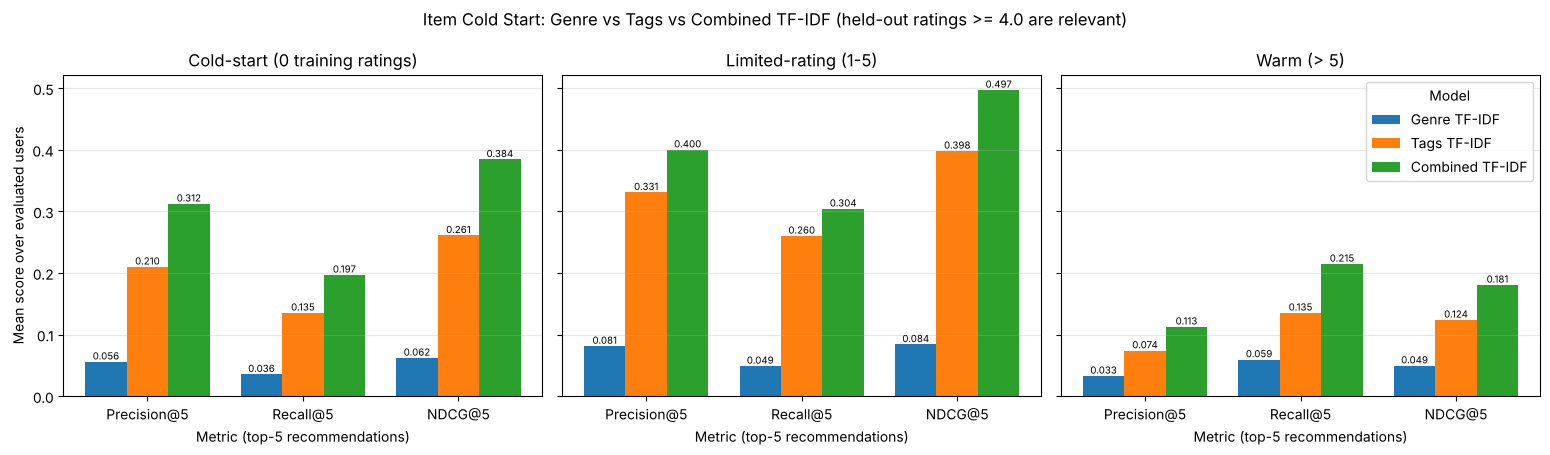

In [22]:
fig1 = ics.plot_item_cold_start_comparison(results, paths["figures_dir"] / "item_cold_start_comparison.png")
plt.show()

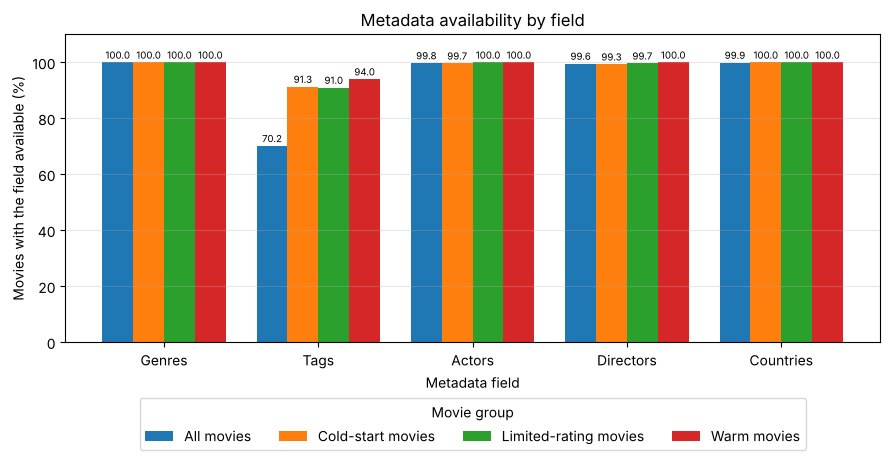

In [23]:
fig2 = ics.plot_metadata_feature_comparison(coverage, paths["figures_dir"] / "metadata_feature_comparison.png")
plt.show()

## 17. Results and Discussion
The next two cells compute the facts that the discussion relies on (best model per group, lift over random, and a popularity diagnostic).

In [24]:
best = results[results.model != "Random (reference)"].sort_values("NDCG@5", ascending=False).groupby("category").head(1)
print("Best TF-IDF model per group by NDCG@5:")
print(best.set_index("category").loc[ics.CATEGORIES, ["model", "Precision@5", "Recall@5", "NDCG@5"]].round(4).to_string())

pivot = results.pivot(index="model", columns="category", values="NDCG@5")[ics.CATEGORIES]
print("\nNDCG@5 as a multiple of the random reference:")
print((pivot.drop(index="Random (reference)") / pivot.loc["Random (reference)"]).round(1).to_string())

Best TF-IDF model per group by NDCG@5:
                          model  Precision@5  Recall@5  NDCG@5
category                                                      
cold_start      Combined TF-IDF       0.3123    0.1969  0.3844
limited_rating  Combined TF-IDF       0.4001    0.3041  0.4971
warm            Combined TF-IDF       0.1125    0.2146  0.1805

NDCG@5 as a multiple of the random reference:
category         cold_start  limited_rating  warm
model                                            
Combined TF-IDF         9.5            13.1  10.0
Genre TF-IDF            1.5             2.2   2.7
Tags TF-IDF             6.4            10.5   6.9


In [25]:
# Diagnostic: do the content scores simply favour popular / metadata-rich movies?
# (400 random evaluation users, cold-start pool, top-10 lists, training data only)
sample_users = np.random.default_rng(RANDOM_STATE).choice(profile_ok[profile_ok].index.to_numpy(), size=400, replace=False)
train_sample = {u: g for u, g in sim_train[sim_train.userID.isin(sample_users)].groupby("userID")}
popularity = heldout[heldout.category == ics.CATEGORY_COLD].groupby("movieID").size().reindex(cold_ids)  # hidden rating counts
rich = pd.Series(tfidf_models["Combined TF-IDF"]["matrix"].getnnz(axis=1),
                 index=movies_prep.movieID).reindex(cold_ids)                                            # metadata richness

diag = []
for name, m in tfidf_models.items():
    freq = pd.Series(0, index=cold_ids)
    for u in sample_users:
        recs = ics.recommend_cold_start_movies(u, train_sample[u], movies_prep, cold_ids,
                                               m["matrix"], movie_id_to_index, top_n=10)
        freq[recs.movieID.to_numpy()] += 1
    diag.append({"model": name,
                 "cold movies ever recommended": int((freq > 0).sum()),
                 "Spearman(rec. frequency, hidden rating count)": freq.corr(popularity, method="spearman")})
print(pd.DataFrame(diag).round(3).to_string(index=False))
print("\nSpearman(hidden rating count, number of non-zero TF-IDF terms of Combined model):",
      round(popularity.corr(rich, method="spearman"), 3))

          model  cold movies ever recommended  Spearman(rec. frequency, hidden rating count)
   Genre TF-IDF                           202                                          0.177
    Tags TF-IDF                           107                                          0.325
Combined TF-IDF                            97                                          0.505

Spearman(hidden rating count, number of non-zero TF-IDF terms of Combined model): 0.601


### Discussion of the results

**1. Which metadata works best.** In all three movie groups the **Combined TF-IDF** model (model C) scored highest on Precision, Recall and NDCG at both K=5 and K=10, followed by **Tags TF-IDF** (B); **Genre TF-IDF** (A) came last and was only slightly better than random ranking (see the "multiple of random" table above). Genre alone offers just 20 distinct terms, so very many movies share *exactly* the same genre vector and receive identical scores; the ranking inside those ties is decided by catalogue order (ascending `movieID`), which is deterministic but arbitrary and may even favour the Genre model slightly. The high Catalog Coverage of the Genre model is a symptom of this weak, tie-heavy signal rather than a strength; the random reference trivially has coverage close to 1.

**2. Strong lift over random - but read it with care.** Models B and C beat the random reference by a wide margin. The diagnostic above shows why this cannot be read as pure "taste matching": the movies that the Tags and Combined models recommend most often are also the movies with the most hidden ratings (positive Spearman correlation), and movies with more hidden ratings tend to have richer metadata (more non-zero TF-IDF terms). A profile built from many liked movies lies close to metadata-rich, popular movies, and popular movies are also the ones with the most relevant held-out ratings. Part of the measured accuracy therefore reflects popularity/metadata richness, and this experiment cannot separate the two. Only a minority of the cold-start pool is ever recommended to the sampled users (see the diagnostic table), which is consistent with that concentration.

**3. Comparing groups.** The content models do not use any item ratings, so cold-start, limited-rating and warm movies are scored by exactly the same mechanism. Differences between the groups come from the *pools* (different movies) and from the *amount of hidden data* (the warm group has only test ratings as ground truth, so far fewer relevant interactions per movie), not from the model working better or worse with more ratings. Compare each group with its own random reference rather than across groups. The practical conclusion is positive: the metadata-based ranking does not need ratings, so a movie can be recommended from its first day. For limited-rating and warm movies the later hybrid module can combine this content score with collaborative signals.

**4. Metadata coverage.** Genres, actors, directors and countries are available for (almost) every movie, but **tags exist for only about 70% of the catalogue**, and movies without tags have an empty vector under Model B (they can never be matched by tags). The simulated cold-start movies have a higher tag share than the catalogue because the selection required >= 20 interactions, i.e. they are relatively popular (and popular movies attract more tags). Real launch-day movies are likely to have fewer tags than our simulated ones.

**5. Limitations (see also Section 14).**
* Held-out ratings are only a proxy for true preference: unrated movies count as non-relevant, and users only rate what they watched.
* Tags are user-generated and appear *after* a movie has been seen by users, so tag-based results (Models B and C) are optimistic for genuinely new movies. A fairer launch-day variant would use genres, actors, directors and countries only; this was not part of the requested models and was not run.
* The split is a random simulation, not a real release timeline; the cold-start movies are not obscure ones.
* One seed and one random draw of 300 movies per group were used, and no confidence intervals were computed, so small differences between models should not be over-interpreted.

## 18. Conclusion
* A complete, leakage-free Item Cold Start pipeline was built on the shared processed data: simulation -> metadata analysis -> three TF-IDF models -> cosine-similarity recommenders -> ranking evaluation.
* Cold-start movies **can** be recommended without any rating history, through both interfaces below.
* Results and figures were written to `outputs/results/` and `outputs/figures/`; every number comes from the executed code above.

**How the other modules can use this component**

In [26]:
# Item-to-item (primary interface) - no ratings needed for the input movie
similar = ics.recommend_similar_movies(movie_id=int(cold_ids[0]), movie_features=movies, top_n=10)

# User-to-item - rank cold-start movies for a user from TRAINING ratings only
recs = ics.recommend_cold_start_movies(
    user_id=example_user, train_ratings=sim_train, movie_features=movies_prep,
    cold_start_movie_ids=cold_ids, tfidf_matrix=tfidf_models["Combined TF-IDF"]["matrix"],
    movie_id_to_index=movie_id_to_index, top_n=10)

print(list(similar.columns), list(recs.columns))

['movieID', 'title', 'similarity_score', 'recommendation_score'] ['movieID', 'title', 'recommendation_score']
